<a href="https://colab.research.google.com/github/SkyWarLimit/PCVK26_17_MIhsanR/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

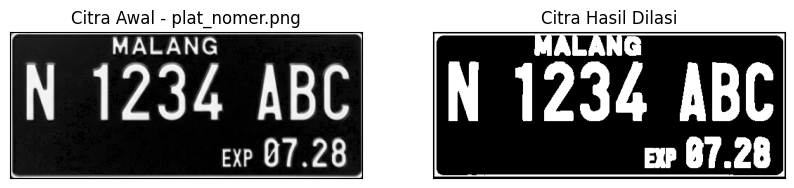

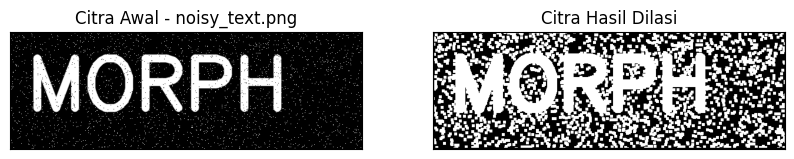

In [ ]:
#dilasi tanpa libary
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
w = 5

for path in image_paths:
    img_d = cv2.imread(path, 0)
    if img_d is not None:
        ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
        imgD = dilasi_citra(thresh, w)
        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(img_d, cmap='gray')
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgD, cmap='gray')
        plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
        plt.show()

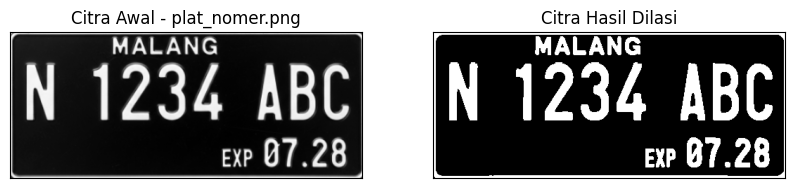

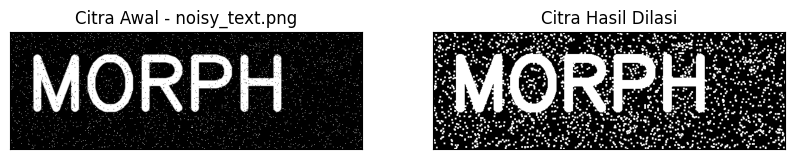

In [ ]:
#dilasi dengan libary
image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
kernel = np.ones((3, 3), np.uint16)

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        ret, thresh = cv2.threshold(img_gray, 127, 225, cv2.THRESH_BINARY)
        dilasi = cv2.dilate(thresh, kernel, iterations=1)
        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(img_gray, cmap='gray')
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(dilasi, cmap='gray')
        plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
        plt.show()

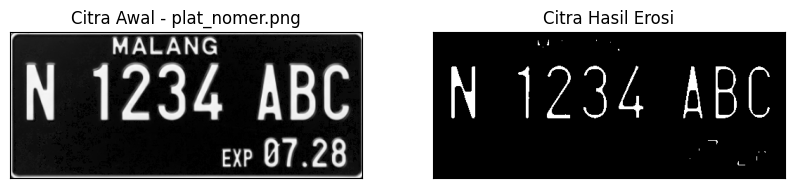

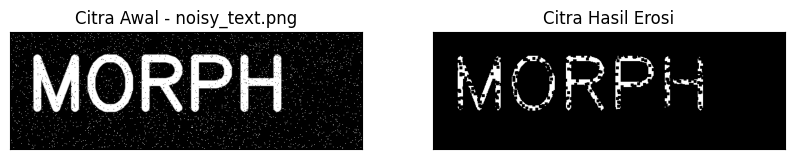

In [ ]:
#Erosi Tanpa Library
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
k = 5

for path in image_paths:
    img_e = cv2.imread(path, 0)
    if img_e is not None:
        ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
        imgE = erosi_citra(thresh1, k)
        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(img_e, cmap='gray')
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(imgE, cmap='gray')
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

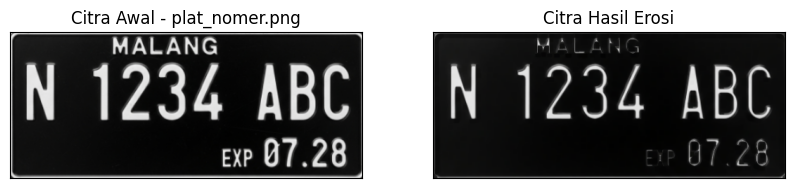

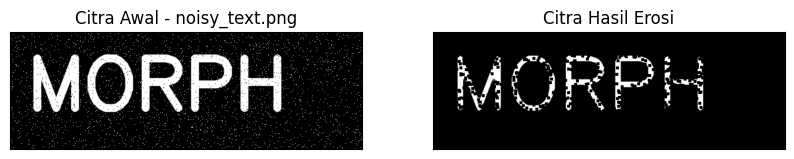

In [ ]:
#EROSI LIBRARY
image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
kernel = np.ones((5, 5), np.uint8)

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        erosion = cv2.erode(img, kernel, iterations=1)
        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB))
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

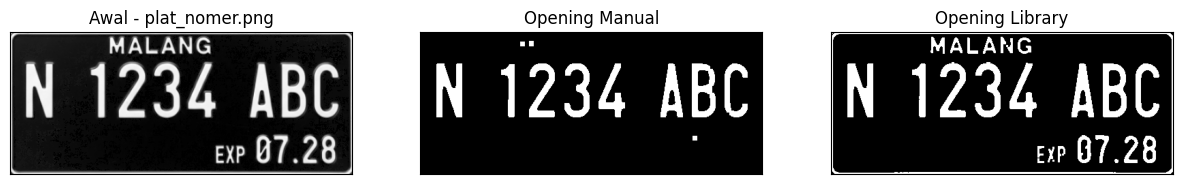

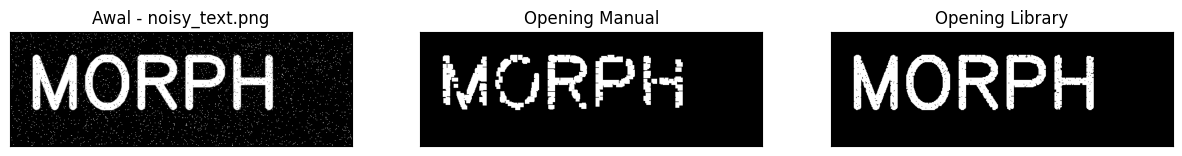

In [ ]:
# Operasi Opening (manual dan tanpa Library) Morphology
image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
k = 7
kernel = np.ones((3, 3), np.uint8)

for path in image_paths:
    img_o = cv2.imread(path, 0)
    if img_o is not None:
        # Manual
        reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
        imgO_manual = dilasi_citra(erosi_citra(thresho, k), k)

        # Library
        openn_lib = cv2.morphologyEx(thresho, cv2.MORPH_OPEN, kernel)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_o, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgO_manual, cmap='gray')
        plt.title('Opening Manual'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(openn_lib, cmap='gray')
        plt.title('Opening Library'), plt.xticks([]), plt.yticks([])
        plt.show()

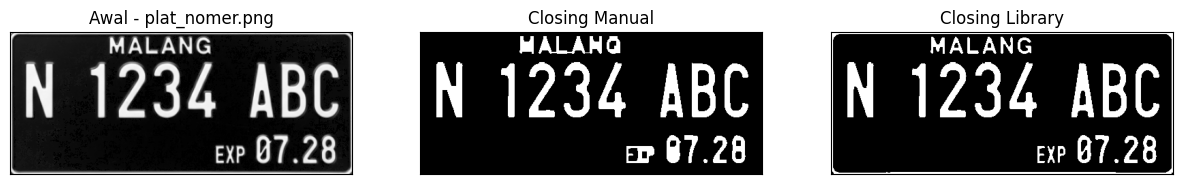

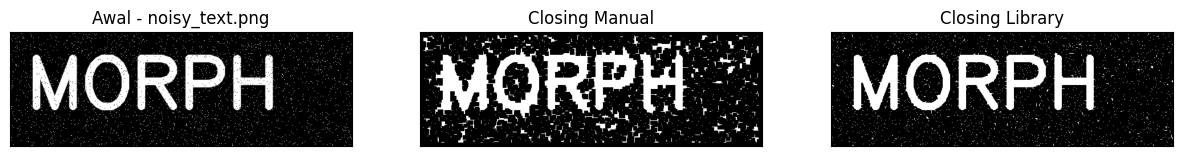

In [ ]:
# operasi closing (manual dan library) morphology
image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
k = 7
kernel = np.ones((3, 3), np.uint8)

for path in image_paths:
    img_c = cv2.imread(path, 0)
    if img_c is not None:
        # Manual
        retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
        imgC_manual = erosi_citra(dilasi_citra(threshc, k), k)

        # Library
        closs_lib = cv2.morphologyEx(threshc, cv2.MORPH_CLOSE, kernel)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_c, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgC_manual, cmap='gray')
        plt.title('Closing Manual'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(closs_lib, cmap='gray')
        plt.title('Closing Library'), plt.xticks([]), plt.yticks([])
        plt.show()

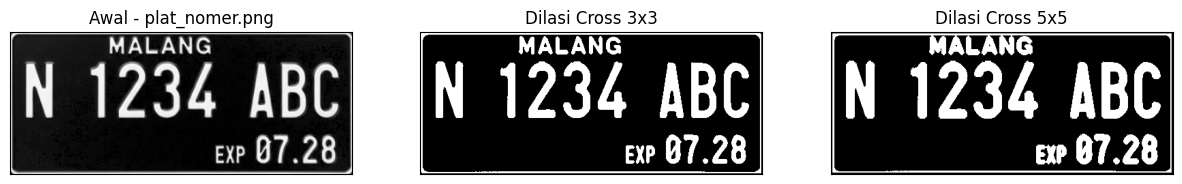

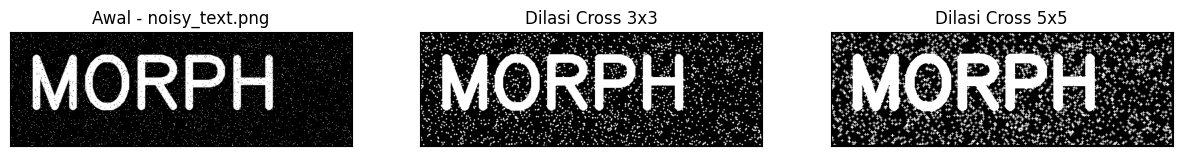

In [ ]:
#Dilasi Cross SE cross 3x3 dan 5x5
def dilasi_citra_cross(F, w, is_5x5=False):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    if is_5x5:
        SED = np.array([[0, 0, 1, 0, 0], [0, 0, 1, 0, 0], [1, 1, 1, 1, 1], [0, 0, 1, 0, 0], [0, 0, 1, 0, 0]], dtype=np.uint8)
    else:
        SED = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_d = cv2.imread(path, 0)
    if img_d is not None:
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD_3 = dilasi_citra_cross(thresh, 3, False)
        imgD_5 = dilasi_citra_cross(thresh, 5, True)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_d, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgD_3, cmap='gray')
        plt.title('Dilasi Cross 3x3'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(imgD_5, cmap='gray')
        plt.title('Dilasi Cross 5x5'), plt.xticks([]), plt.yticks([])
        plt.show()

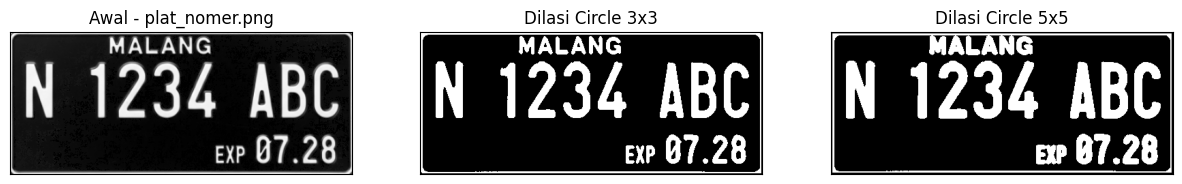

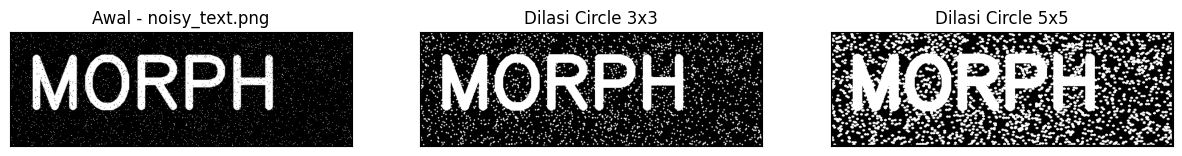

In [ ]:
#Dilasi Circular SE 3x3 dan 5x5
def dilasi_citra_circ(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_d = cv2.imread(path, 0)
    if img_d is not None:
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD_3 = dilasi_citra_circ(thresh, 3)
        imgD_5 = dilasi_citra_circ(thresh, 5)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_d, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgD_3, cmap='gray')
        plt.title('Dilasi Circle 3x3'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(imgD_5, cmap='gray')
        plt.title('Dilasi Circle 5x5'), plt.xticks([]), plt.yticks([])
        plt.show()

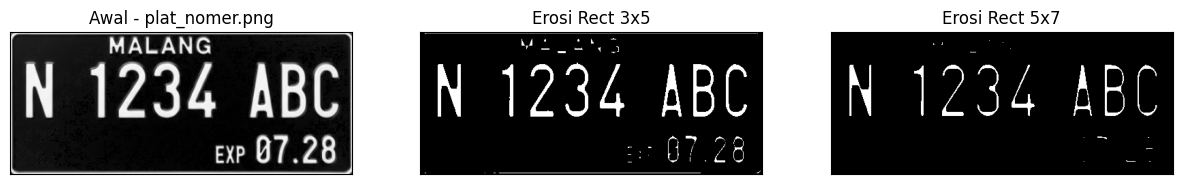

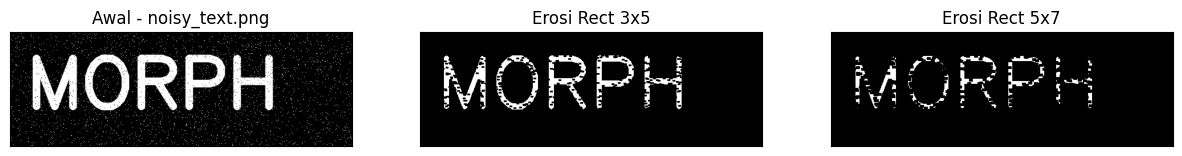

In [ ]:
#Erosi Cross SE 3x5 dan 5x7
def erosi_citra_rect(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            imgE[i, j] = np.min(temp * SE)
    return imgE

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_e = cv2.imread(path, 0)
    if img_e is not None:
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE_3x5 = erosi_citra_rect(thresh1, 5, 3)
        imgE_5x7 = erosi_citra_rect(thresh1, 7, 5)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_e, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgE_3x5, cmap='gray')
        plt.title('Erosi Rect 3x5'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(imgE_5x7, cmap='gray')
        plt.title('Erosi Rect 5x7'), plt.xticks([]), plt.yticks([])
        plt.show()

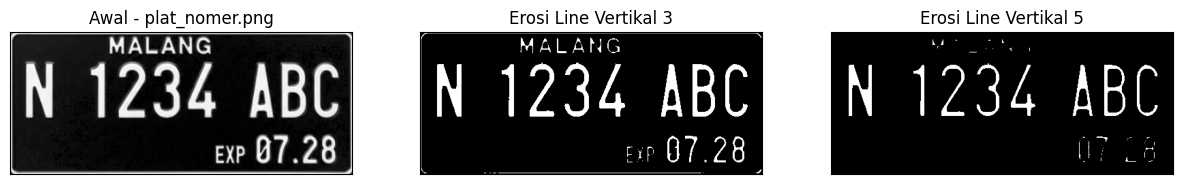

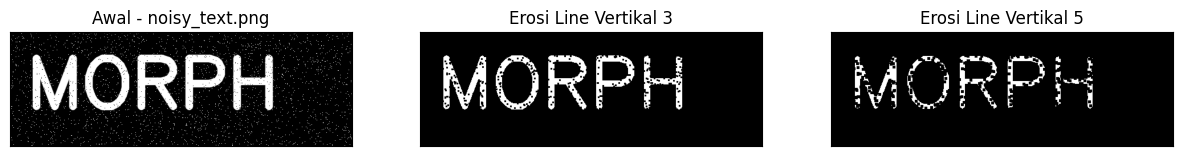

In [ ]:
#Erosi Line Vertikal SE 3 dan 5
def erosi_citra_line(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            imgE[i, j] = np.min(temp * SE)
    return imgE

image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_e = cv2.imread(path, 0)
    if img_e is not None:
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE_3 = erosi_citra_line(thresh1, 3)
        imgE_5 = erosi_citra_line(thresh1, 5)

        plt.figure(figsize=(15, 4))
        plt.subplot(131), plt.imshow(img_e, cmap='gray')
        plt.title(f'Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(132), plt.imshow(imgE_3, cmap='gray')
        plt.title('Erosi Line Vertikal 3'), plt.xticks([]), plt.yticks([])
        plt.subplot(133), plt.imshow(imgE_5, cmap='gray')
        plt.title('Erosi Line Vertikal 5'), plt.xticks([]), plt.yticks([])
        plt.show()

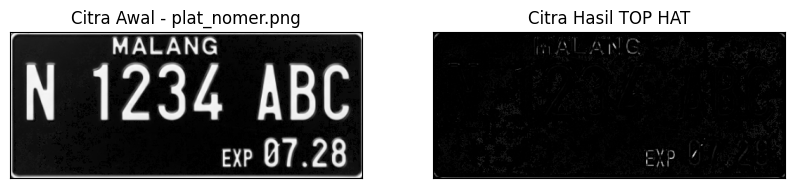

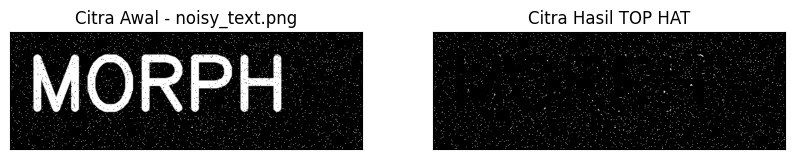

In [ ]:
#top hat dengan SE 3x3
image_paths = ['/content/drive/MyDrive/PCVK/plat_nomer.png', '/content/drive/MyDrive/PCVK/noisy_text.png']
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

for path in image_paths:
    img = cv2.imread(path, 0)
    if img is not None:
        tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(img, cmap='gray')
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
        plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
        plt.show()

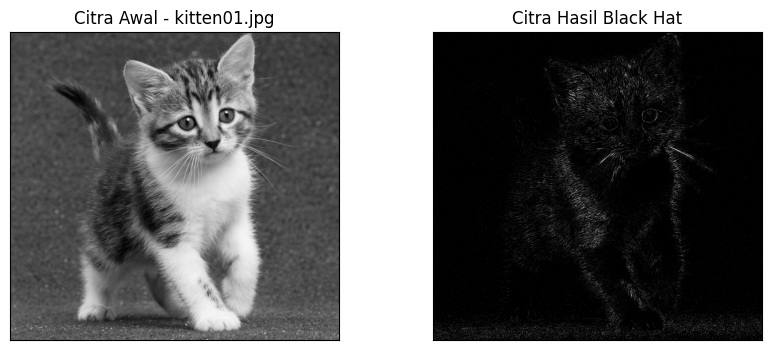

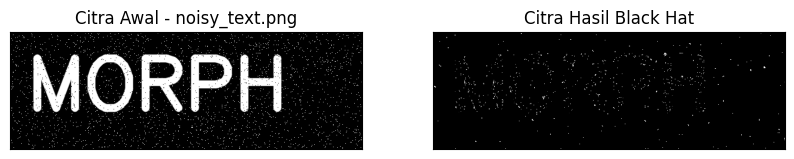

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_paths = ['/content/drive/MyDrive/PCVK/kitten01.jpg', '/content/drive/MyDrive/PCVK/noisy_text.png']
filterSize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        # Pengecekan dimensi agar aman jika gambar sudah grayscale
        if len(img.shape) == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

        plt.figure(figsize=(10, 4))
        plt.subplot(121), plt.imshow(img, cmap='gray')
        plt.title(f'Citra Awal - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(blackhat, cmap='gray')
        plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
        plt.show()

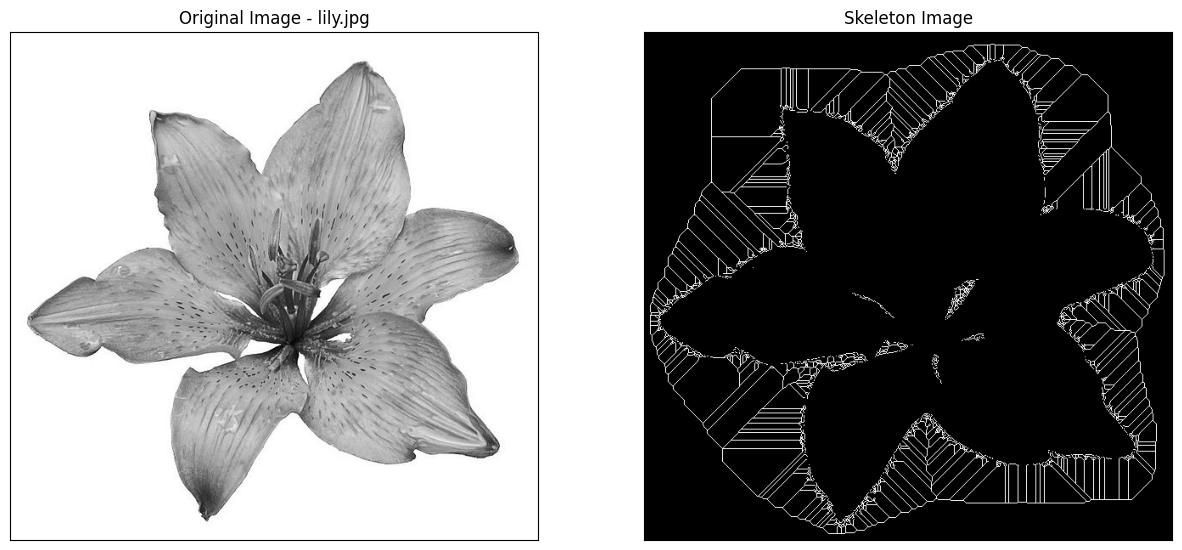

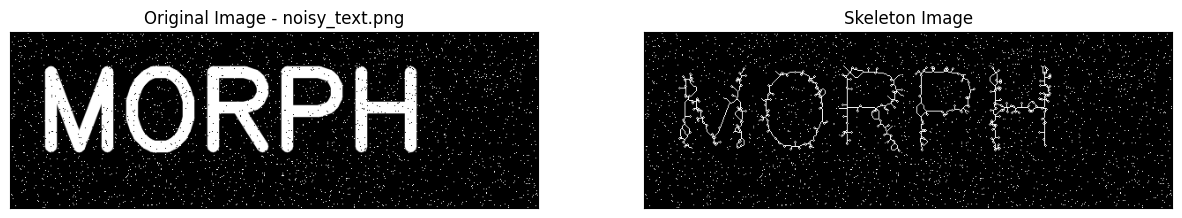

In [ ]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

image_paths = ['/content/drive/MyDrive/PCVK/lily.jpg', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img = cv.imread(path, 0)
    if img is not None:
        binary = img > filters.threshold_triangle(img)
        binary_cp = binary.copy()
        binary_cp[binary_cp == True] = 1
        binary_cp[binary_cp == False] = 0

        # skeletonize image
        skeleton = skeletonize(binary_cp)

        plt.figure(figsize=(15, 7))
        plt.subplot(121), plt.imshow(img, cmap='gray')
        plt.title(f'Original Image - {path.split("/")[-1]}'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(skeleton, cmap='gray')
        plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
        plt.show()

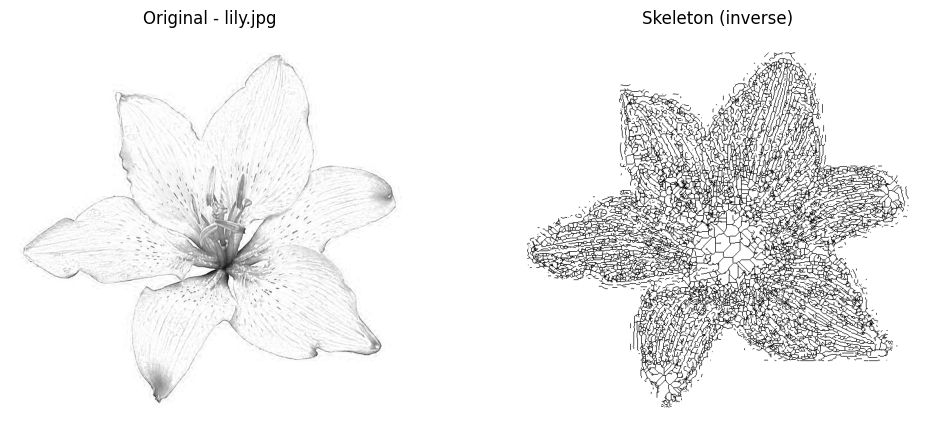

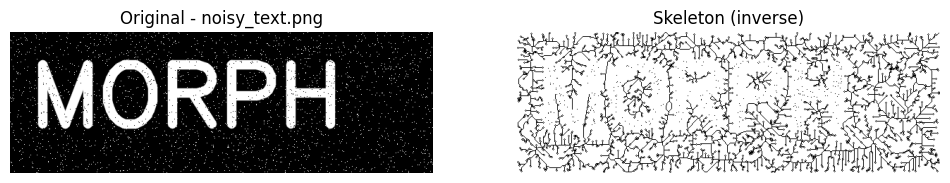

In [ ]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

image_paths = ['/content/drive/MyDrive/PCVK/lily.jpg', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_raw = io.imread(path)
    # Ambil channel pertama jika gambar RGB, atau biarkan jika sudah grayscale
    img = img_raw[..., 0] if img_raw.ndim == 3 else img_raw

    binary = img < filters.threshold_triangle(img)
    skeleton = skeletonize(binary)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'Original - {path.split("/")[-1]}')
    ax[0].set_axis_off()
    ax[1].imshow(skeleton, cmap='gray_r')
    ax[1].set_title('Skeleton (inverse)')
    ax[1].set_axis_off()
    plt.show()

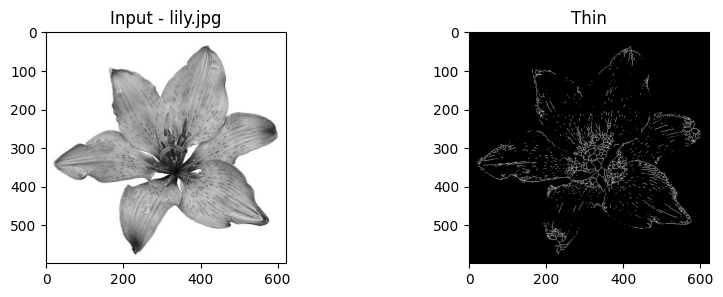

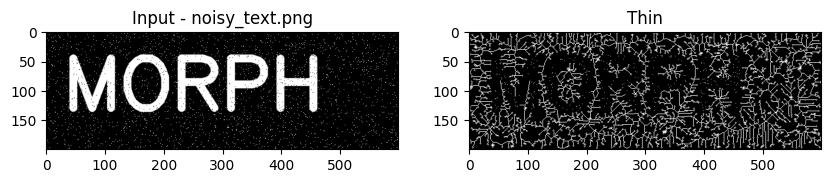

In [ ]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image_paths = ['/content/drive/MyDrive/PCVK/lily.jpg', '/content/drive/MyDrive/PCVK/noisy_text.png']

for path in image_paths:
    img_raw = io.imread(path)
    # Konversi aman ke grayscale jika gambar RGB
    if img_raw.ndim == 3:
        img_gray = color.rgb2gray(img_raw)
    else:
        img_gray = img_raw

    image = img_as_float(img_gray)
    image_binary = image < 0.5
    out_thin = morphology.thin(image_binary)

    f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
    ax0.imshow(image, cmap='gray')
    ax0.set_title(f'Input - {path.split("/")[-1]}')
    ax1.imshow(out_thin, cmap='gray')
    ax1.set_title('Thin')
    plt.show()